# Normalización, lematización y vectorización de un libro completo

**Checkpoints 3, 4 y 5 — Procesamiento de Lenguaje Natural (Hybridge)**

Pipeline de limpieza aplicado a un libro en `.txt`:

1. Carga robusta del texto (codificación y caracteres rotos)
2. Limpieza básica con expresiones regulares
3. Tokenización con spaCy
4. Eliminación de ruido (stopwords y puntuación)
5. Lematización y normalización a minúsculas
6. Comparativa Stemming (NLTK) vs Lematización (spaCy)
7. Exportación del corpus limpio

Representación vectorial (Checkpoint 4):

9. Corpus por oraciones
10. Bag-of-Words con `CountVectorizer`
11. TF-IDF con `TfidfVectorizer`
12. TF-IDF por capítulo y similitud entre capítulos
13. Espacio vectorial en 3D con PCA

Semántica distribucional (Checkpoint 5):

14. Word2Vec: CBOW vs Skip-gram
15. Aritmética semántica
16. Espacio de embeddings en 3D

## 0. Configuración

In [1]:
import re
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from gensim.models import Word2Vec
from nltk.stem import SnowballStemmer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Book file and output folder (relative to the project root)
RUTA_LIBRO = Path("libro.txt")
CARPETA_SALIDA = Path("salida")
CARPETA_SALIDA.mkdir(exist_ok=True)

# Load the Spanish model; NER is not needed for cleaning, so we disable it for speed
nlp = spacy.load("es_core_news_sm", disable=["ner"])
nlp.max_length = 3_000_000  # allow long texts (a whole book)

print(f"spaCy {spacy.__version__} | pipeline: {nlp.pipe_names}")

spaCy 3.8.16 | pipeline: ['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer']


## 1. Carga del texto

Los `.txt` descargados de internet suelen traer problemas de codificación: acentos que aparecen como `Ã­` o `Ã±` (*mojibake*). Esta función prueba la codificación correcta y repara ese caso antes de procesar nada, porque un acento roto hace que spaCy lematice mal la palabra.

In [2]:
def cargar_texto(ruta: Path) -> str:
    """Read a text file trying common encodings and repair double-encoded UTF-8."""
    raw = ruta.read_bytes()
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            texto = raw.decode(enc)
            break
        except UnicodeDecodeError:
            continue

    # Repair mojibake such as 'tenÃ\xada' -> 'tenía' (UTF-8 bytes read as Latin-1)
    if re.search(r"Ã[\x80-\xbf¡-¿]", texto):
        try:
            texto = texto.encode("cp1252", errors="strict").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            texto = texto.encode("latin-1", errors="ignore").decode("utf-8", errors="ignore")
    return texto


texto_original = cargar_texto(RUTA_LIBRO)
print(f"Caracteres: {len(texto_original):,}")
print(texto_original[:500])

Caracteres: 458,735
The Project Gutenberg eBook of El sombrero de tres picos
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using


## 2. Limpieza básica (regex)

Antes de tokenizar quitamos lo que no es parte de la obra:

- Encabezado y licencia de Project Gutenberg (si el libro viene de ahí)
- Saltos de línea que parten las oraciones a la mitad
- Espacios repetidos y comillas tipográficas inconsistentes
- Introducción, notas y vocabulario en inglés del editor (es una edición escolar de 1907).

In [3]:
def quitar_gutenberg(texto: str) -> str:
    """Keep only the body of a Project Gutenberg book (no-op for other sources)."""
    inicio = re.search(r"\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG.*?\*\*\*", texto, re.I)
    fin = re.search(r"\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG", texto, re.I)
    desde = inicio.end() if inicio else 0
    hasta = fin.start() if fin else len(texto)
    return texto[desde:hasta]

# Section headings of the editor's English apparatus that follow the novel
PATRON_APENDICES = re.compile(r"^\s*(NOTES|VOCABULARY|FOOTNOTES)\s*$", re.M)


def recortar_novela(texto: str) -> str:
    """Keep only Alarcón's text: from his dedication up to the editor's notes/vocabulary."""
    inicio = re.search(r"^\s*AL SEÑOR\s*$", texto, re.M)
    desde = inicio.start() if inicio else 0
    # Search after the dedication so the table-of-contents entries are skipped
    fin = PATRON_APENDICES.search(texto, desde)
    hasta = fin.start() if fin else len(texto)
    print(f"Recorte: caracteres {desde:,} a {hasta:,} de {len(texto):,}")
    return texto[desde:hasta]


# Paragraphs added by Project Gutenberg volunteers (credits, transcriber notes)
PATRON_CREDITOS = re.compile(
    r"^(produced by|e-?text prepared by|transcriber'?s? notes?|nota del transcriptor"
    r"|end of (the )?project gutenberg)",
    re.I,
)


def limpiar_texto(texto: str) -> list[str]:
    """Normalize whitespace/quotes and return the text split into paragraphs."""
    texto = quitar_gutenberg(texto)
    texto = recortar_novela(texto)
    texto = texto.replace("\r\n", "\n")
    texto = re.sub(r"[“”«»]", '"', texto)
    texto = re.sub(r"[‘’]", "'", texto)
    texto = re.sub(r"_+", "", texto)  # Gutenberg italics markers

    # A blank line separates paragraphs; single line breaks are just wrapping
    parrafos = re.split(r"\n\s*\n", texto)
    parrafos = [re.sub(r"\s+", " ", p).strip() for p in parrafos]
    return [p for p in parrafos if len(p) > 1 and not PATRON_CREDITOS.match(p)]

parrafos = limpiar_texto(texto_original)
print(f"Párrafos: {len(parrafos):,}")
for p in parrafos[:3]:
    print("-", p[:150])

print("Último párrafo:", parrafos[-1][:200])

Recorte: caracteres 19,938 a 174,582 de 438,901
Párrafos: 940
- AL SEÑOR
- D. JOSÉ SALVADOR DE SALVADOR
- Dedico esta obra.
Último párrafo: FIN.


## 3. Tokenización

Procesamos el libro párrafo por párrafo con `nlp.pipe`. Es más rápido que pasar todo el texto de golpe y no satura la memoria con libros largos.

In [4]:
docs = list(nlp.pipe(parrafos, batch_size=64))
tokens_totales = [token for doc in docs for token in doc]

print(f"--- Tokenización (Total tokens: {len(tokens_totales):,}) ---")
print([t.text for t in tokens_totales[:20]])

--- Tokenización (Total tokens: 30,395) ---
['AL', 'SEÑOR', 'D.', 'JOSÉ', 'SALVADOR', 'DE', 'SALVADOR', 'Dedico', 'esta', 'obra', '.', 'P.', 'A.', 'DE', 'ALARCÓN', '.', 'JULIO', 'de', '1874', '.']


## 4. Eliminación de ruido (stopwords y puntuación)

In [5]:
def es_relevante(token) -> bool:
    """Keep only alphabetic content words (drops stopwords, punctuation, numbers, spaces)."""
    return token.is_alpha and not token.is_stop

tokens_relevantes = [t for t in tokens_totales if es_relevante(t)]
tokens_ruido = [t for t in tokens_totales if t.is_stop]

print("--- Filtrado de Stop Words ---")
print("Palabras eliminadas (ruido):", [t.text for t in tokens_ruido[:10]], "...")
print("Palabras conservadas (contenido):", [t.text for t in tokens_relevantes[:10]], "...")
reduccion = 100 * (1 - len(tokens_relevantes) / len(tokens_totales))
print(f"Reducción: de {len(tokens_totales):,} a {len(tokens_relevantes):,} tokens ({reduccion:.1f}% menos)")

--- Filtrado de Stop Words ---
Palabras eliminadas (ruido): ['AL', 'DE', 'esta', 'DE', 'de', 'DEL', 'Pocos', 'aun', 'a', 'los'] ...
Palabras conservadas (contenido): ['SEÑOR', 'JOSÉ', 'SALVADOR', 'SALVADOR', 'Dedico', 'obra', 'ALARCÓN', 'JULIO', 'PREFACIO', 'AUTOR'] ...
Reducción: de 30,395 a 9,893 tokens (67.5% menos)


## 5. Lematización y normalización

Cada palabra se reduce a su lema y se pasa a minúsculas, para que *hablo*, *hablaré* y *habla* cuenten como el mismo concepto: *hablar*.

In [6]:
tokens_normalizados = [t.lemma_.lower() for t in tokens_relevantes]

# Words whose lemma differs from the lowercase form (most informative examples)
cambios = Counter(
    (t.text.lower(), t.lemma_.lower())
    for t in tokens_relevantes
    if t.text.lower() != t.lemma_.lower()
)

print("--- Lematización y Normalización ---")
print(f"Tokens procesados: {len(tokens_normalizados):,}")
print(f"Vocabulario antes: {len({t.text.lower() for t in tokens_relevantes}):,} formas distintas")
print(f"Vocabulario después: {len(set(tokens_normalizados)):,} lemas distintos")
print("\nTransformaciones más frecuentes (palabra → lema):")
for (original, lema), n in cambios.most_common(15):
    print(f"  {original:>15} → {lema:<15} ({n} veces)")

--- Lematización y Normalización ---
Tokens procesados: 9,893
Vocabulario antes: 4,656 formas distintas
Vocabulario después: 3,702 lemas distintos

Transformaciones más frecuentes (palabra → lema):
          exclamó → exclamar        (28 veces)
             ojos → ojo             (22 veces)
          hubiera → haber           (16 veces)
              iba → ir              (16 veces)
             años → año             (15 veces)
            manos → mano            (15 veces)
             digo → decir           (15 veces)
            viene → venir           (14 veces)
            picos → pico            (13 veces)
          parecía → parecer         (13 veces)
        respondió → responder       (13 veces)
            horas → hora            (13 veces)
         contestó → contestar       (12 veces)
            media → medio           (12 veces)
            cosas → cosa            (11 veces)


## 6. Stemming vs Lematización

El **stemming** (NLTK) corta sufijos con reglas fijas, sin entender la palabra. La **lematización** (spaCy) usa el contexto y un diccionario para dar la forma real. Comparamos ambas sobre los verbos y sustantivos más frecuentes del libro.

In [7]:
stemmer = SnowballStemmer("spanish")

# Pick the most frequent verbs and nouns from the book itself, so the table is never empty
frecuentes = Counter(
    t.text.lower() for t in tokens_relevantes if t.pos_ in ("VERB", "NOUN")
    and t.text.lower() != t.lemma_.lower()
)
ejemplos = {}
for t in tokens_relevantes:
    palabra = t.text.lower()
    if palabra in dict(frecuentes.most_common(15)) and palabra not in ejemplos:
        ejemplos[palabra] = t.lemma_.lower()

df = pd.DataFrame(
    [
        {
            "Original": palabra,
            "Stemming (corte)": stemmer.stem(palabra),
            "Lematización (diccionario)": lema,
            "¿Coinciden?": stemmer.stem(palabra) == lema,
        }
        for palabra, lema in ejemplos.items()
    ]
)
print(df.to_string(index=False))
print(f"\nEl stem coincide con el lema en {df['¿Coinciden?'].mean():.0%} de los casos.")

 Original Stemming (corte) Lematización (diccionario)  ¿Coinciden?
     años             años                        año        False
    picos              pic                       pico        False
 contestó          contest                  contestar        False
    cosas              cos                       cosa        False
 continuó          continu                  continuar        False
    manos              man                       mano        False
    viene             vien                      venir        False
     digo              dig                      decir        False
    hacía              hac                      hacer        False
     uvas             uvas                        uva        False
    horas              hor                      horas        False
     ojos             ojos                        ojo        False
  parecía            parec                    parecer        False
  exclamó           exclam                   exclamar        F

## 7. Lemas más frecuentes

In [8]:
frecuencias = Counter(tokens_normalizados).most_common(20)
df_frec = pd.DataFrame(frecuencias, columns=["Lema", "Frecuencia"])
print(df_frec.to_string(index=False))

      Lema  Frecuencia
     lucas         156
corregidor         155
       tío         140
 frasquita         123
      señá         103
     señor          92
     mujer          62
    molino          58
     decir          54
   garduña          53
       ver          51
     haber          50
    hombre          49
      casa          44
     noche          43
    tiempo          40
    ciudad          40
  alguacil          38
    puerta          37
     venir          36


## 8. Corpus limpio y exportación

Armamos un documento lematizado por párrafo (listo para `CountVectorizer` o `TfidfVectorizer` en la siguiente etapa) y lo guardamos en `salida/`.

In [9]:
corpus_lematizado = []  # one cleaned document per paragraph

for doc in docs:
    lemas = [t.lemma_.lower() for t in doc if es_relevante(t)]
    if lemas:
        corpus_lematizado.append(" ".join(lemas))

ruta_corpus = CARPETA_SALIDA / "corpus_lematizado.txt"
ruta_corpus.write_text("\n".join(corpus_lematizado), encoding="utf-8")
df_frec.to_csv(CARPETA_SALIDA / "frecuencias.csv", index=False, encoding="utf-8")

print(f"Documentos en el corpus: {len(corpus_lematizado):,}")
print(f"Guardado en: {ruta_corpus}")
print("\nEjemplo:", corpus_lematizado[0][:300])

Documentos en el corpus: 909
Guardado en: salida/corpus_lematizado.txt

Ejemplo: señor


## 9. Corpus por oraciones

Para vectorizar, cada **documento** será una oración del libro, como en la clase. Los `docs` de spaCy ya traen la división en oraciones (`doc.sents`), así que no hace falta volver a procesar el texto.

Al revisar el vocabulario apareció un detalle: el lema más frecuente era *él*. spaCy separa los pronombres pegados al verbo (*verlo → ver él*, *decirme → decir yo*, *poniéndose → poner él*), y esos pronombres no pasaban por el filtro de stopwords porque el filtro mira la palabra original, no el lema. La función `lemas_de` separa esas piezas y descarta las que son stopwords.

In [10]:
STOPWORDS = nlp.Defaults.stop_words


def lemas_de(tokens) -> list[str]:
    """Lemmas of the relevant tokens, dropping enclitic pronouns ('verlo' -> 'ver él' -> 'ver')."""
    lemas = []
    for t in tokens:
        if es_relevante(t):
            lemas += [parte for parte in t.lemma_.lower().split() if parte not in STOPWORDS]
    return lemas


pegados = Counter((t.text.lower(), t.lemma_.lower()) for t in tokens_relevantes if " " in t.lemma_)
print(f"Tokens con pronombre pegado: {sum(pegados.values())}")
print("Ejemplos:", pegados.most_common(5))

corpus_oraciones = []  # one cleaned document per sentence
for doc in docs:
    for oracion in doc.sents:
        lemas = lemas_de(oracion)
        if lemas:
            corpus_oraciones.append(" ".join(lemas))

print(f"\nTotal de oraciones procesadas: {len(corpus_oraciones):,}")
for oracion in corpus_oraciones[20:23]:
    print("-", oracion)

Tokens con pronombre pegado: 310
Ejemplos: [(('verlo', 'ver él'), 7), (('poniéndose', 'poner él'), 7), (('decirme', 'decir yo'), 5), (('dirigiéndose', 'dirigir él'), 4), (('díjole', 'dijo él'), 4)]

Total de oraciones procesadas: 1,293
- andar año oer diverso versión aventura molinero corregidora labio gracioso aldea cortijo orden difunto repela leer letra molde romances ciego famoso romancero inolvidable agustín durán
- fondo asunto resultar idéntico zumbón terriblemente epigramático lección dramático moral enamorar pueblo forma mecanismo accidental procedimiento casual diferir muchísimo relato pastor recitar cortijada versión correr impresa tapar oído muchacha honesto exponer madre sacar punto extremar pervertir grosero patán provincia caso tradicional sabroso discreto pulcro resultar versión clásico repela
- tiempo concebir propósito restablecer cosa devolver peregrina historio primitivo carácter dudamos salir librado dudar


## 10. Bag-of-Words (`CountVectorizer`)

Cada oración se convierte en un vector de conteos: una posición por cada palabra del vocabulario y, en cada posición, cuántas veces aparece esa palabra en la oración. Se pierde el orden, pero el texto ya es numérico.

In [11]:
bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(corpus_oraciones)
vocab_bow = bow_vectorizer.get_feature_names_out()

celdas = X_bow.shape[0] * X_bow.shape[1]
print(f"Matriz BoW: {X_bow.shape[0]:,} oraciones x {X_bow.shape[1]:,} palabras")
print(f"Valores distintos de cero: {X_bow.nnz:,} de {celdas:,} ({100 * (1 - X_bow.nnz / celdas):.2f}% son ceros)")
print(f"Palabras por oración en promedio: {X_bow.nnz / X_bow.shape[0]:.1f}")

# One sentence seen as a vector: only its non-zero positions
i = 21
fila = X_bow[i]
print(f"\nOración {i}: {corpus_oraciones[i]}")
print(pd.DataFrame({"Palabra": vocab_bow[fila.indices], "Posición": fila.indices, "Conteo": fila.data}).to_string(index=False))

Matriz BoW: 1,293 oraciones x 3,532 palabras
Valores distintos de cero: 9,224 de 4,566,876 (99.80% son ceros)
Palabras por oración en promedio: 7.1

Oración 21: fondo asunto resultar idéntico zumbón terriblemente epigramático lección dramático moral enamorar pueblo forma mecanismo accidental procedimiento casual diferir muchísimo relato pastor recitar cortijada versión correr impresa tapar oído muchacha honesto exponer madre sacar punto extremar pervertir grosero patán provincia caso tradicional sabroso discreto pulcro resultar versión clásico repela
      Palabra  Posición  Conteo
       pastor      2411       1
    cortijada       842       1
      recitar      2763       1
     muchacha      2208       1
        madre      2039       1
       repela      2821       1
     resultar      2862       2
        sacar      2938       1
      versión      3414       2
        fondo      1497       1
       asunto       323       1
     idéntico      1734       1
       zumbón      3517    

## 11. TF-IDF (`TfidfVectorizer`)

TF-IDF pesa cada palabra según qué tan frecuente es en el documento (**TF**) y qué tan rara es en toda la colección (**IDF**). Una palabra que sale en muchas oraciones recibe un IDF bajo, y una que sale en pocas recibe un IDF alto.

Comparamos las palabras más frecuentes del libro contra su IDF.

In [12]:
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(corpus_oraciones)
vocab_tfidf = tfidf_vectorizer.get_feature_names_out()
assert (vocab_tfidf == vocab_bow).all()  # same tokenization, same columns

df_idf = pd.DataFrame({
    "Lema": vocab_tfidf,
    "Frecuencia": np.asarray(X_bow.sum(axis=0)).ravel(),
    "Oraciones": np.asarray((X_bow > 0).sum(axis=0)).ravel(),
    "IDF": tfidf_vectorizer.idf_.round(2),
})

print(f"Matriz TF-IDF: {X_tfidf.shape[0]:,} x {X_tfidf.shape[1]:,}")
print(f"IDF mínimo: {df_idf.IDF.min()} | IDF máximo: {df_idf.IDF.max()}")
print("\n--- Palabras más frecuentes (IDF más bajo) ---")
print(df_idf.sort_values("Frecuencia", ascending=False).head(10).to_string(index=False))
print("\n--- Palabras con 5+ apariciones pero en pocas oraciones (IDF más alto) ---")
print(df_idf[df_idf.Frecuencia >= 5].sort_values("IDF", ascending=False).head(10).to_string(index=False))

Matriz TF-IDF: 1,293 x 3,532
IDF mínimo: 3.14 | IDF máximo: 7.47

--- Palabras más frecuentes (IDF más bajo) ---
      Lema  Frecuencia  Oraciones  IDF
     lucas         156        149 3.15
corregidor         155        151 3.14
       tío         140        133 3.27
 frasquita         123        120 3.37
      señá         103        102 3.53
     señor          92         91 3.64
     mujer          62         61 4.04
    molino          58         56 4.12
   garduña          53         52 4.20
    hombre          49         47 4.29

--- Palabras con 5+ apariciones pero en pocas oraciones (IDF más alto) ---
     Lema  Frecuencia  Oraciones  IDF
      oro           8          3 6.78
  querido           5          4 6.56
  asustar           5          4 6.56
  alegrar           5          4 6.56
  ventana           5          4 6.56
consistir           6          4 6.56
      san           5          4 6.56
   ladrón           5          4 6.56
imposible           7          4 6.56
  

## 12. TF-IDF por capítulo

Con oraciones como documentos, casi ninguna palabra se repite dentro de la misma oración: el TF vale 1 casi siempre y TF-IDF termina midiendo solo rareza. Para ver la idea completa, usamos los **36 capítulos** de la novela como documentos.

- En cada capítulo comparamos sus palabras más frecuentes contra las de mayor TF-IDF. Los nombres de los protagonistas aparecen en casi todos los capítulos, así que IDF los baja y suben las palabras que distinguen ese capítulo.
- Con la similitud coseno entre vectores TF-IDF buscamos qué capítulos se parecen más entre sí.

In [13]:
# A chapter starts with its Roman numeral alone on a line
PATRON_CAPITULO = re.compile(r"^\s*[IVXL]+\.?\s*$", re.M)

texto_novela = recortar_novela(quitar_gutenberg(texto_original))
bloques = PATRON_CAPITULO.split(texto_novela)[1:]  # [0] is the dedication and preface

# The title is the first paragraph of each chapter
titulos = [re.sub(r"\s+", " ", re.split(r"\n\s*\n", b.strip())[0]).strip(" .") for b in bloques]
capitulos = [re.sub(r"\s+", " ", re.sub(r"_+", "", b)).strip() for b in bloques]
corpus_capitulos = [" ".join(lemas_de(doc)) for doc in nlp.pipe(capitulos)]
print(f"Capítulos: {len(corpus_capitulos)}")

bow_cap = CountVectorizer()
X_bow_cap = bow_cap.fit_transform(corpus_capitulos)
tfidf_cap = TfidfVectorizer()
X_tfidf_cap = tfidf_cap.fit_transform(corpus_capitulos)
vocab_cap = tfidf_cap.get_feature_names_out()


def top_palabras(fila, n=5) -> str:
    """The n columns with the highest value in a sparse row."""
    valores = fila.toarray().ravel()
    return ", ".join(vocab_cap[valores.argsort()[::-1][:n]])


df_cap = pd.DataFrame({
    "Cap.": range(1, len(capitulos) + 1),
    "Título": [t[:38] for t in titulos],
    "Más frecuentes (BoW)": [top_palabras(f) for f in X_bow_cap],
    "Más distintivas (TF-IDF)": [top_palabras(f) for f in X_tfidf_cap],
})
pd.set_option("display.max_colwidth", None)
df_cap

Recorte: caracteres 19,938 a 174,582 de 438,901


Capítulos: 36


,Cap.,Título,Más frecuentes (BoW),Más distintivas (TF-IDF)
0,1,DE CUÁNDO SUCEDIÓ LA COSA,"venir, dios, gracia, mundo, batalla","gracia, corona, gaceta, pirineo, suponer"
1,2,DE CÓMO VIVÍA ENTONCES LA GENTE,"tiempo, dichosísimo, comer, chocolate, andalucía","dichosísimo, puchero, chocolate, andalucía, tiempo"
2,3,DO UT DES,"oro, molinero, tiempo, molino, merced","oro, merced, servir, macarro, invierno"
3,4,UNA MUJER VISTA POR FUERA,"frasquita, señá, lucas, tío, molino","frasquita, señá, parecer, andaluz, clérigo"
4,5,UN HOMBRE VISTO POR FUERA Y POR DENTRO,"lucas, tío, hombre, voz, perfección","perfección, mozo, resistir, general, padre"
5,6,HABILIDADES DE LOS DOS CÓNYUGES,"tío, lucas, frasquita, señá, casa","imposible, jazmín, criadero, cuyo, producir"
6,7,EL FONDO DE LA FELICIDAD,"tío, consistir, lucas, señá, frasquita","consistir, felicidad, fondo, amar, tío"
7,8,EL HOMBRE DEL SOMBRERO DE TRES PICOS,"corregidor, negro, capa, señor, ciudad","capa, especie, sombrero, negro, grana"
8,9,"¡ARRE, BURRA!","corregidor, hombre, marido, lucas, frasquita","manuel, josefa, incapaz, hombre, marido"
9,10,DESDE LA PARRA,"lucas, corregidor, parra, frasquita, tío","parra, gustar, lucas, creer, corregidor"


--- Capítulos más parecidos (similitud coseno sobre TF-IDF) ---
0.349  Cap. 24 (UN REY DE ENTONCES)  <->  Cap. 27 (¡FAVOR AL REY!)
0.328  Cap. 15 (DESPEDIDA EN PROSA)  <->  Cap. 27 (¡FAVOR AL REY!)
0.321  Cap. 15 (DESPEDIDA EN PROSA)  <->  Cap. 24 (UN REY DE ENTONCES)
0.294  Cap. 31 (LA PENA DEL TALIÓN)  <->  Cap. 33 (PUES ¿Y TÚ?)
0.289  Cap. 14 (LOS CONSEJOS DE GARDUÑA)  <->  Cap. 22 (GARDUÑA SE MULTIPLICA)


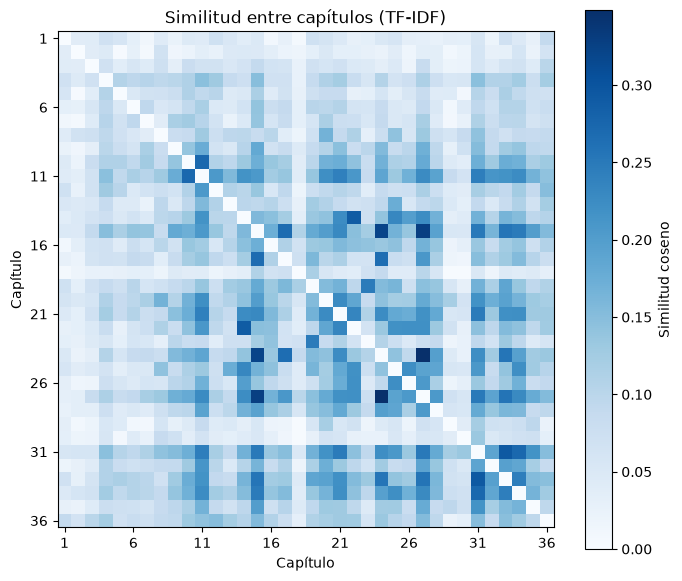

In [14]:
similitud = cosine_similarity(X_tfidf_cap)
np.fill_diagonal(similitud, 0)  # a chapter is always identical to itself

pares = [
    (similitud[a, b], a + 1, b + 1)
    for a in range(len(similitud))
    for b in range(a + 1, len(similitud))
]
print("--- Capítulos más parecidos (similitud coseno sobre TF-IDF) ---")
for valor, a, b in sorted(pares, reverse=True)[:5]:
    print(f"{valor:.3f}  Cap. {a} ({titulos[a - 1][:30]})  <->  Cap. {b} ({titulos[b - 1][:30]})")

plt.figure(figsize=(8, 7))
plt.imshow(similitud, cmap="Blues")
plt.colorbar(label="Similitud coseno")
plt.title("Similitud entre capítulos (TF-IDF)")
plt.xlabel("Capítulo")
plt.ylabel("Capítulo")
marcas = range(0, len(similitud), 5)
plt.xticks(marcas, [m + 1 for m in marcas])
plt.yticks(marcas, [m + 1 for m in marcas])
plt.savefig(CARPETA_SALIDA / "similitud_capitulos.png", dpi=120, bbox_inches="tight")
plt.show()

## 13. Espacio vectorial en 3D (PCA)

Cada palabra es un vector con una dimensión por oración (1,000+ dimensiones), imposible de graficar. Con **PCA** reducimos a 3 componentes principales y comparamos cómo se acomodan las palabras en BoW y en TF-IDF.

Usamos la función de la clase, pero solo con las 40 palabras más frecuentes: con todo el vocabulario (miles de etiquetas) la gráfica no se puede leer.

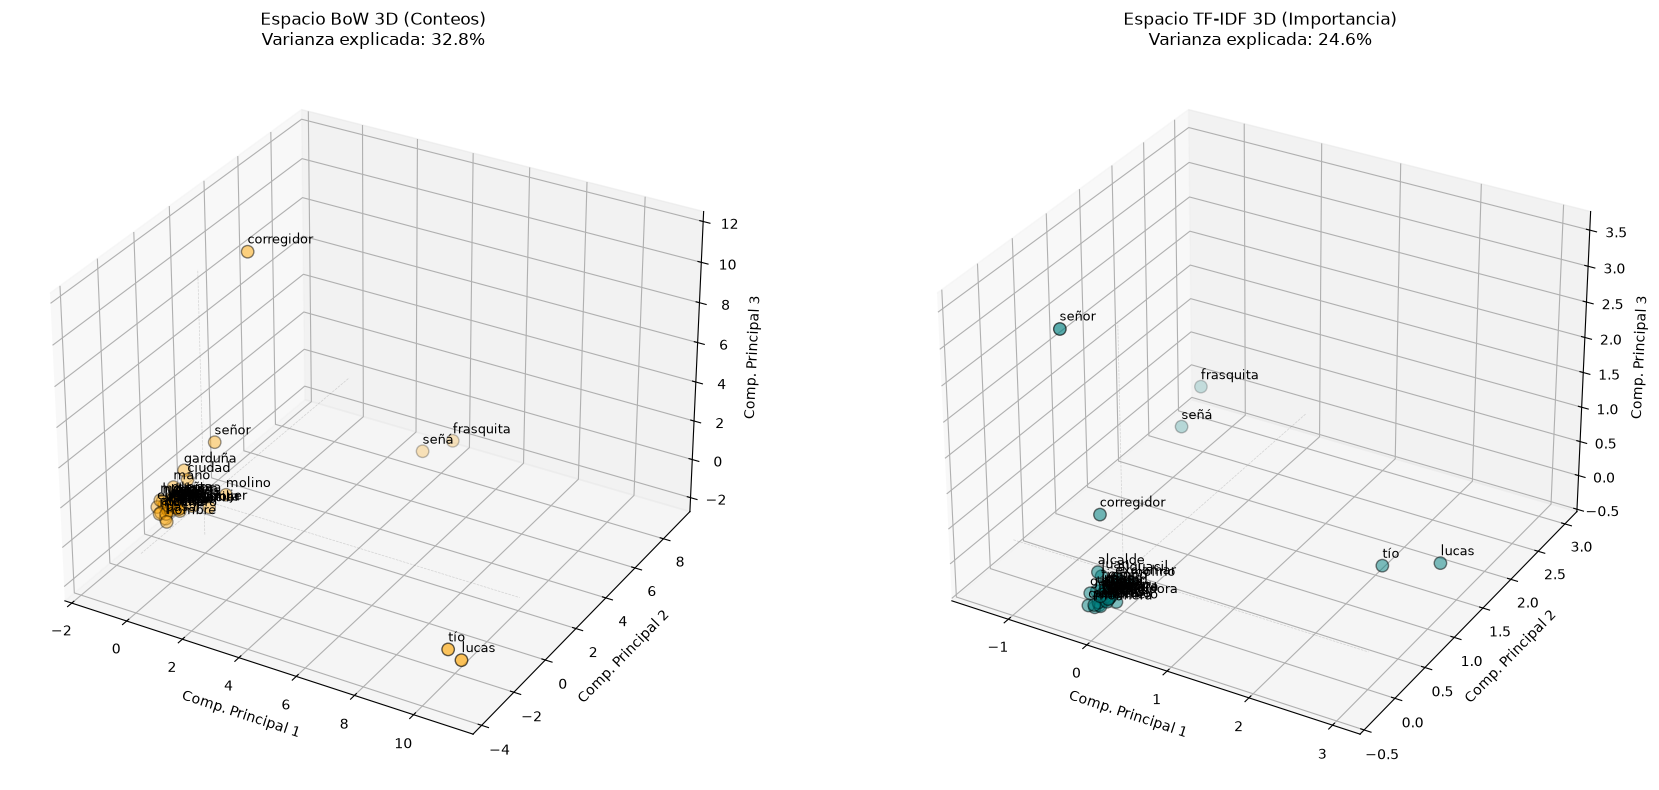

In [15]:
N_PALABRAS = 40


def graficar_palabras_3d(ax, matriz, vocabulario, titulo, color_puntos):
    # 1. Transpose: rows = words, columns = sentences (contexts)
    matriz_palabras = matriz.T

    # 2. PCA down to 3 dimensions
    pca = PCA(n_components=3)
    coords = pca.fit_transform(matriz_palabras.toarray())
    x, y, z = coords[:, 0], coords[:, 1], coords[:, 2]

    # 3. 3D scatter, with labels floating slightly above each point
    ax.scatter(x, y, z, c=color_puntos, s=80, edgecolors="k", alpha=0.8, depthshade=True)
    desfase = 0.03 * (z.max() - z.min())
    for i, palabra in enumerate(vocabulario):
        ax.text(x[i], y[i], z[i] + desfase, palabra, fontsize=9)

    varianza = 100 * pca.explained_variance_ratio_.sum()
    ax.set_title(f"{titulo}\nVarianza explicada: {varianza:.1f}%")
    ax.set_xlabel("Comp. Principal 1")
    ax.set_ylabel("Comp. Principal 2")
    ax.set_zlabel("Comp. Principal 3")

    # Reference lines through the origin
    ax.plot([0, 0], [0, 0], [z.min(), z.max()], c="grey", ls="--", lw=0.5, alpha=0.3)
    ax.plot([x.min(), x.max()], [0, 0], [0, 0], c="grey", ls="--", lw=0.5, alpha=0.3)
    ax.plot([0, 0], [y.min(), y.max()], [0, 0], c="grey", ls="--", lw=0.5, alpha=0.3)


# Columns of the N most frequent words (same order in both matrices)
top = df_idf.sort_values("Frecuencia", ascending=False).index[:N_PALABRAS]

fig = plt.figure(figsize=(18, 8))
ax1 = fig.add_subplot(121, projection="3d")
graficar_palabras_3d(ax1, X_bow[:, top], vocab_bow[top], "Espacio BoW 3D (Conteos)", "orange")
ax2 = fig.add_subplot(122, projection="3d")
graficar_palabras_3d(ax2, X_tfidf[:, top], vocab_tfidf[top], "Espacio TF-IDF 3D (Importancia)", "teal")

plt.tight_layout()
fig.savefig(CARPETA_SALIDA / "espacio_vectorial_3d.png", dpi=120)
plt.show()

## 14. Semántica distribucional: Word2Vec

BoW y TF-IDF **cuentan** palabras y dan vectores enormes llenos de ceros, donde *molino* y *molinero* están tan lejos como *molino* y *obispo*. Word2Vec **predice**: entrena una red neuronal pequeña para adivinar palabras a partir de su contexto, y los pesos que aprende son vectores densos (*embeddings*). Se apoya en la **hipótesis distribucional**: palabras que aparecen en contextos parecidos tienen significados parecidos.

Hay dos variantes:

- **CBOW**: recibe el contexto y predice la palabra del centro.
- **Skip-gram**: recibe la palabra del centro y predice su contexto. Suele funcionar mejor con corpus pequeños como este libro.

Configuración:

- **Entrada:** cada oración como lista de lemas, reutilizando `lemas_de` para que no se cuelen los pronombres pegados.
- **Vocabulario:** `min_count=3` descarta palabras que salen una o dos veces, porque no hay contexto suficiente para aprenderlas.
- **Reproducibilidad:** `workers=1` y una función hash fija (`zlib.crc32`), para que los vectores salgan iguales en cada ejecución.

In [16]:
oraciones_tokens = []  # one list of lemmas per sentence
for doc in docs:
    for oracion in doc.sents:
        lemas = lemas_de(oracion)
        if len(lemas) > 1:  # a single word has no context to learn from
            oraciones_tokens.append(lemas)

print(f"Oraciones de entrenamiento: {len(oraciones_tokens):,}")
print(f"Palabras de entrenamiento: {sum(map(len, oraciones_tokens)):,}")
print("Ejemplo:", oraciones_tokens[0])

parametros = dict(
    vector_size=50,  # embedding dimensions (hidden layer size)
    window=5,        # words of context on each side
    min_count=3,
    epochs=200,      # many passes, since the book is small
    workers=1,
    seed=42,
    hashfxn=lambda palabra: zlib.crc32(palabra.encode()),  # Python's hash() changes on every run
)
modelo_cbow = Word2Vec(oraciones_tokens, sg=0, **parametros)
modelo_sg = Word2Vec(oraciones_tokens, sg=1, **parametros)

print(f"\nVocabulario aprendido: {len(modelo_sg.wv):,} palabras x {modelo_sg.wv.vector_size} dimensiones")
print("\nAsí ve el modelo la palabra 'molino' (primeras 10 de 50 dimensiones):")
print(modelo_sg.wv["molino"][:10].round(3))

Oraciones de entrenamiento: 1,106
Palabras de entrenamiento: 9,207
Ejemplo: ['josé', 'salvador', 'salvador']



Vocabulario aprendido: 707 palabras x 50 dimensiones

Así ve el modelo la palabra 'molino' (primeras 10 de 50 dimensiones):
[-0.07  -0.291 -0.337  0.716  0.909  0.352 -0.325  0.611 -0.586  0.246]


In [17]:
def vecinos(modelo, palabra, n=5) -> str:
    """The n nearest words in the embedding space, with their cosine similarity."""
    return ", ".join(f"{p} ({s:.2f})" for p, s in modelo.wv.most_similar(palabra, topn=n))


palabras = ["lucas", "frasquita", "corregidor", "garduña", "molino", "burra"]
pd.DataFrame({
    "Palabra": palabras,
    "CBOW": [vecinos(modelo_cbow, p) for p in palabras],
    "Skip-gram": [vecinos(modelo_sg, p) for p in palabras],
})

,Palabra,CBOW,Skip-gram
0,lucas,"objeto (0.50), vivo (0.50), tío (0.50), engañar (0.44), caminar (0.42)","tío (0.98), consistir (0.47), venir (0.46), cargado (0.45), apoderar (0.45)"
1,frasquita,"acercar (0.50), replicar (0.44), esposa (0.43), pálido (0.40), resto (0.39)","señá (0.96), molino (0.53), acercar (0.49), resto (0.48), pálido (0.45)"
2,corregidor,"márchese (0.41), inmediatamente (0.41), continuar (0.37), entrar (0.37), señá (0.36)","señor (0.64), garduña (0.55), inmediatamente (0.52), racimo (0.51), ciudad (0.51)"
3,garduña,"amo (0.62), distancia (0.47), esposo (0.43), ministro (0.42), escalera (0.41)","corregidor (0.55), criado (0.48), escalera (0.48), ministro (0.46), abajo (0.46)"
4,molino,"plazoletilla (0.53), atravesar (0.49), señá (0.49), discurrir (0.45), empedrado (0.44)","frasquita (0.53), señá (0.53), viaje (0.47), lágrima (0.46), emparrado (0.46)"
5,burra,"montar (0.57), bestia (0.55), yesca (0.53), corral (0.53), dirección (0.53)","corral (0.60), aparejar (0.56), montar (0.53), oportuno (0.50), saludar (0.49)"


## 15. Aritmética semántica

Si los embeddings capturan significado, se puede operar con ellos: en modelos grandes, *rey − hombre + mujer ≈ reina*. Lo probamos con las parejas de la novela, el tío Lucas con la señá Frasquita y el Corregidor con la Corregidora. Con un libro de ~9 mil palabras, este tipo de relaciones apenas empieza a aparecer.

In [18]:
pares = [("lucas", "frasquita"), ("corregidor", "corregidora"), ("tío", "señá"), ("burra", "montar"), ("lucas", "obispo")]
print("--- Similitud coseno entre pares (Skip-gram) ---")
for a, b in pares:
    print(f"{a:>11} <-> {b:<12} {modelo_sg.wv.similarity(a, b):.3f}")

analogias = [
    (["lucas", "corregidora"], ["frasquita"]),   # Frasquita is to Lucas as the Corregidora is to ? (corregidor)
    (["corregidor", "frasquita"], ["corregidora"]),  # the Corregidora is to the Corregidor as Frasquita is to ? (lucas)
]
print("\n--- Analogías ---")
for positivos, negativos in analogias:
    resultado = modelo_sg.wv.most_similar(positive=positivos, negative=negativos, topn=5)
    expresion = f"{positivos[0]} - {negativos[0]} + {positivos[1]}"
    print(f"{expresion:<35} ≈ " + ", ".join(f"{p} ({s:.2f})" for p, s in resultado))

--- Similitud coseno entre pares (Skip-gram) ---
      lucas <-> frasquita    0.389
 corregidor <-> corregidora  0.216
        tío <-> señá         0.437
      burra <-> montar       0.532
      lucas <-> obispo       0.217

--- Analogías ---
lucas - frasquita + corregidora     ≈ tío (0.52), labio (0.43), marido (0.43), venir (0.40), letra (0.40)
corregidor - corregidora + frasquita ≈ señá (0.72), molino (0.51), vuelta (0.44), andalucía (0.42), hombre (0.41)


## 16. Espacio de embeddings en 3D

Reducimos las 50 dimensiones a 3 con PCA y comparamos CBOW contra Skip-gram, con las mismas 40 palabras más frecuentes del modelo. A diferencia de BoW y TF-IDF, aquí cada punto es un vector denso aprendido, y la cercanía refleja contextos compartidos.

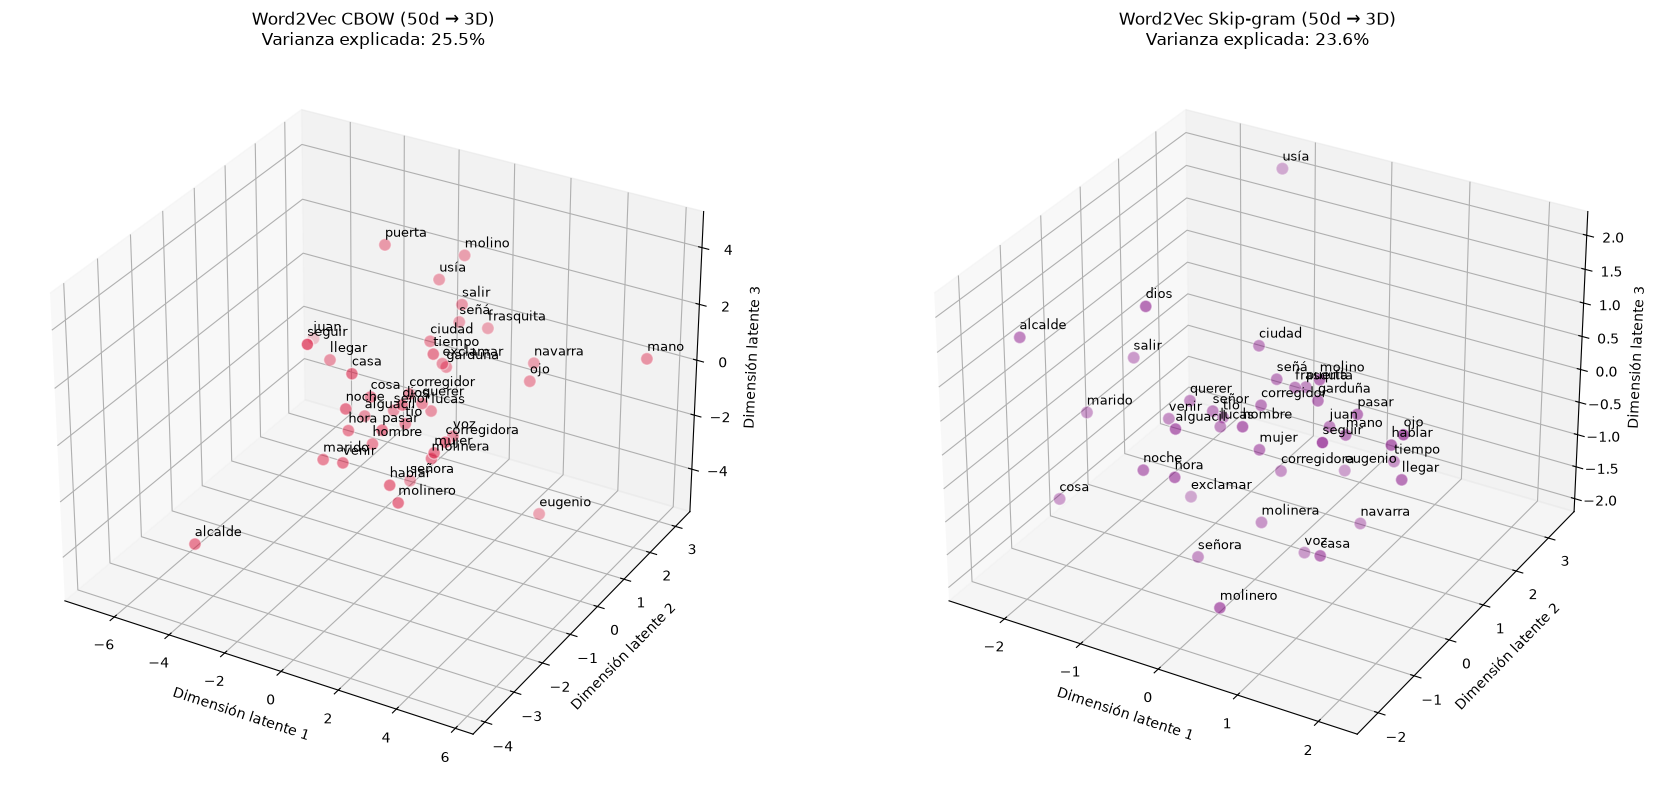

In [19]:
def graficar_embeddings_3d(ax, modelo, palabras, titulo, color_puntos):
    vectores = modelo.wv[palabras]
    pca = PCA(n_components=3)
    coords = pca.fit_transform(vectores)
    x, y, z = coords[:, 0], coords[:, 1], coords[:, 2]

    ax.scatter(x, y, z, c=color_puntos, s=80, edgecolors="white", alpha=0.8)
    desfase = 0.03 * (z.max() - z.min())
    for i, palabra in enumerate(palabras):
        ax.text(x[i], y[i], z[i] + desfase, palabra, fontsize=9)

    varianza = 100 * pca.explained_variance_ratio_.sum()
    ax.set_title(f"{titulo}\nVarianza explicada: {varianza:.1f}%")
    ax.set_xlabel("Dimensión latente 1")
    ax.set_ylabel("Dimensión latente 2")
    ax.set_zlabel("Dimensión latente 3")


# index_to_key is sorted by frequency, and both models share the same vocabulary
frecuentes = modelo_sg.wv.index_to_key[:N_PALABRAS]

fig = plt.figure(figsize=(18, 8))
ax1 = fig.add_subplot(121, projection="3d")
graficar_embeddings_3d(ax1, modelo_cbow, frecuentes, "Word2Vec CBOW (50d → 3D)", "crimson")
ax2 = fig.add_subplot(122, projection="3d")
graficar_embeddings_3d(ax2, modelo_sg, frecuentes, "Word2Vec Skip-gram (50d → 3D)", "purple")

plt.tight_layout()
fig.savefig(CARPETA_SALIDA / "embeddings_word2vec_3d.png", dpi=120)
plt.show()

## Conclusiones

- **Conocer la fuente es parte de la limpieza.** El archivo era una edición escolar de 1907 con prefacio, introducción, notas y vocabulario en inglés. Solo un tercio del texto era la novela. Sin recortarlo, las palabras más frecuentes eran *to*, *the* y *of*, y spaCy inventaba lemas como *one → onir* o *name → namir*.
- **Las stopwords son la mayor parte del texto.** Al quitar stopwords y puntuación, los tokens bajaron de 30,395 a 9,893 (67.5% menos).
- **La lematización compacta el vocabulario.** Las 4,656 formas distintas quedaron en 3,702 lemas, porque conjugaciones y plurales se agrupan (*exclamó → exclamar*, *ojos → ojo*).
- **Stemming y lematización casi nunca coinciden.** El stemming produce raíces que no son palabras (*respond*, *exclam*, *dig*), mientras que la lematización devuelve palabras reales (*responder*, *exclamar*, *decir*).
- **El resultado refleja la obra.** Los lemas más frecuentes son los personajes y lugares de la novela: Lucas, el Corregidor, la señá Frasquita, el molino y Garduña.

### Vectorización (Checkpoint 4)

- **Los lemas también esconden stopwords.** spaCy separa los pronombres pegados al verbo (*verlo → ver él*), y 310 tokens traían uno. Sin quitarlos, *él* era la palabra más frecuente de la matriz.
- **Bag-of-Words es casi todo ceros.** Las 1,293 oraciones por 3,532 palabras dan una matriz con 99.80% de ceros: cada oración usa en promedio 7 palabras del vocabulario. Por eso sklearn la guarda como matriz dispersa.
- **IDF castiga a los protagonistas.** *Lucas* y *corregidor* aparecen en ~150 oraciones y tienen el IDF más bajo (3.1), mientras que palabras como *oro* o *ladrón* llegan a 6.8. Con oraciones como documento casi ninguna palabra se repite dentro del documento, así que TF-IDF mide sobre todo rareza.
- **Por capítulo, TF-IDF sí encuentra el tema.** Con conteos, los capítulos se parecen porque todos hablan del tío Lucas y la señá Frasquita. Con TF-IDF salen las palabras que dan título al capítulo: *uva, obispo, primicia, racimo* en «Diezmos y primicias»; *capa, sombrero, negro, grana* en «El hombre del sombrero de tres picos»; *puchero, chocolate, Andalucía* en «De cómo vivía entonces la gente».
- **La similitud coseno agrupa capítulos de la misma trama.** Los más parecidos son el 24 y el 27 (0.349): los dos giran alrededor del alcalde Juan López y Toñuelo, igual que el 15.
- **PCA en 3D pierde mucha información.** Las 3 componentes explican 32.8% de la varianza en BoW y 24.6% en TF-IDF. Los protagonistas quedan separados y casi todas las demás palabras se amontonan cerca del origen.

### Semántica distribucional (Checkpoint 5)

- **Skip-gram aprende mejor que CBOW con un libro pequeño.** Con solo 9,207 palabras de entrenamiento, CBOW da vecinos casi al azar (*lucas → objeto, vivo*). Skip-gram encuentra las parejas que siempre van juntas: *lucas ↔ tío* (0.98) y *frasquita ↔ señá* (0.96), porque el narrador siempre dice «el tío Lucas» y «la señá Frasquita».
- **Los vecinos reflejan contextos, no definiciones.** *burra* queda cerca de *corral*, *aparejar* y *montar*, y *garduña* cerca de *corregidor*, *criado* y *ministro*: el alguacil siempre aparece sirviendo a su amo. Es la hipótesis distribucional en acción.
- **Los vectores densos son mucho más compactos.** Cada palabra pasa de un vector de 1,293 posiciones casi todas en cero (BoW) a uno de 50 números reales, y aun así dos palabras distintas pueden quedar cerca si se usan igual.
- **La aritmética semántica no alcanza con un solo libro.** *corregidor − corregidora + frasquita* da *señá* y no *lucas*, y *lucas − frasquita + corregidora* da *tío* y *marido* pero no *corregidor*. El modelo aprendió quién aparece con quién, pero para que funcione *rey − hombre + mujer ≈ reina* hacen falta millones de oraciones, como en GloVe o los modelos preentrenados.
- **En 3D los embeddings se reparten mejor.** En BoW y TF-IDF casi todas las palabras quedaban amontonadas en el origen. Con Word2Vec las 40 palabras se distribuyen por todo el espacio, aunque las 3 componentes solo explican 25.5% (CBOW) y 23.6% (Skip-gram) de la varianza.